In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# 1) Generate the plots for Figures 2 and 3 (PCT positions)

In [15]:
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from pathlib import Path
from collections import Counter
from matplotlib.lines import Line2D

if not os.path.exists('../figures'):
    os.mkdir('../figures')
    
gen_data_loc = '../data/output/llama3:8b/'
pct_data_loc = '../data/pct'
prompting_loc = '../data/prompting'

In [16]:
answer_map = {'Strongly disagree': 0, 'Strongly Disagree': 0, 'Disagree': 1, 'Agree': 2, 'Strongly agree': 3, 'Strongly Agree': 3, 'None':-1}
personas = json.load(open(f'{prompting_loc}/personas.json', 'r'))
personas['age'] = [float(i) for i in personas['age']]
personas = {i:j for i, j in personas.items() if i != 'party'}

categories = list(personas.keys())

models = ['llama3:8b']

questions = [l.strip() for l in open(f"{pct_data_loc}/political_compass_questions.txt", 'r').readlines()]
q_map = {q.strip():i for i,q in enumerate(questions, start=1)}
# print(q_map)

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

e0 = 0.38
s0 = 2.41
econv = [
    #[4.5, 2.5, -2.5, -4.5],
    [7, 5, 0, -2],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [7, 5, 0, -2],
    [-7, -5, 0, 2],
    [6, 4, 0, -2],
    [7, 5, 0, -2],
    [-8, -6, 0, 2],
    [8, 6, 0, -2],
    [8, 6, 0, -1],
    [7, 5, 0, -3],
    [8, 6, 0, -1],
    [-7, -5, 0, 2],
    [-7, -5, 0, 1],
    [-6, -4, 0, 2],
    [6, 4, 0, -1],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [-8, -6, 0, 1],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [-10, -8, 0, 1],
    [-5, -4, 0, 1],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [-9, -8, 0, 1],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0]
]

socv = [
    [0, 0, 0, 0],
    [-8, -6, 0, 2],
    [7, 5, 0, -2],
    [-7, -5, 0, 2],
    [-7, -5, 0, 2],
    [-6, -4, 0, 2],
    [7, 5, 0, -2],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [-6, -4, 0, 2],
    [7, 6, 0, -2],
    [-5, -4, 0, 2],
    [0, 0, 0, 0],
    [8, 4, 0, -2],
    [-7, -5, 0, 2],
    [-7, -5, 0, 3],
    [6, 4, 0, -3],
    [6, 3, 0, -2],
    [-7, -5, 0, 3],
    [-9, -7, 0, 2],
    [-8, -6, 0, 2],
    [7, 6, 0, -2],
    [-7, -5, 0, 2],
    [-6, -4, 0, 2],
    [-7, -4, 0, 2],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [7, 5, 0, -3],
    [-9, -6, 0, 2],
    [-8, -6, 0, 2],
    [-8, -6, 0, 2],
    [-6, -4, 0, 2],
    [-8, -6, 0, 2],
    [-7, -5, 0, 2],
    [-8, -6, 0, 2],
    [-5, -3, 0, 2],
    [-7, -5, 0, 2],
    [7, 5, 0, -2],
    [-6, -4, 0, 2],
    [-7, -5, 0, 2],
    [-6, -4, 0, 2],
    [0, 0, 0, 0],
    [-7, -5, 0, 2],
    [-6, -4, 0, 2],
    [-7, -6, 0, 2],
    [7, 6, 0, -2],
    [7, 5, 0, -2],
    [8, 6, 0, -2],
    [-8, -6, 0, 2],
    [-6, -4, 0, 2]
]

def political_compass_values(answers):
    sumE = 0
    sumS = 0

    for i in range(62):
        if answers[i] != -1:
            sumE += econv[i][answers[i]]
            sumS += socv[i][answers[i]]

    valE = sumE / 8.0
    valS = sumS / 19.5

    valE += e0
    valS += s0

    valE = round((valE + 1e-15) * 100) / 100
    valS = round((valS + 1e-15) * 100) / 100

    return valE, valS

def get_values(answers: pd.DataFrame):
    answer_mat = np.rint(np.array([[answer_map[a] for a in row[1:]] for row in answers.to_numpy()]).mean(-1)).astype(np.int32)
    loc = political_compass_values(answer_mat)
    return loc
                             
sns.set(style="whitegrid", font_scale=1.5)
plt.rcParams['font.family'] = 'DejaVu Sans'

def political_compass_base_plot(figsize):
    fig, ax = plt.subplots(figsize=figsize, clip_on=False)

    ax.set_xlim((-10, 10))
    ax.set_ylim((-10, 10))

    ax.set_xticks(list(range(-10, 11)))
    ax.set_xticklabels([])
    ax.set_yticks(list(range(-10, 11)))
    ax.set_yticklabels([])
    ax.axhline(y=0, color='k')
    ax.axvline(x=0, color='k')

    ax.set_facecolor('white')
    for sp in ax.spines:
        ax.spines[sp].set_color('#AAAAAA')
        ax.spines[sp].set_visible(True)

    plt.grid(color='grey', linestyle='--', linewidth=0.5)

    # Define the quadrants with the original color maps
    extent = [0, 10, 0, 10]
    arr = np.array([[1, 1], [1, 1]])
    ax.imshow(arr, extent=extent, cmap='winter', interpolation='none', alpha=0.15)

    extent = [-10, 0, 0, 10]
    arr = np.array([[1, 1], [1, 1]])
    ax.imshow(arr, extent=extent, cmap='autumn', interpolation='none', alpha=0.15)

    extent = [-10, 0, -10, 0]
    arr = np.array([[1, 1], [1, 1]])
    ax.imshow(arr, extent=extent, cmap='summer', interpolation='none', alpha=0.15)

    extent = [0, 10, -10, 0]
    arr = np.array([[1, 1], [1, 1]])
    ax.imshow(arr, extent=extent, cmap='spring_r', interpolation='none', alpha=0.15)

    ax.annotate("Economic right", xy=(9.8, -0.75), fontsize=16, ha='right')
    ax.annotate("Economic left", xy=(-9.8, -0.75), fontsize=16)
    ax.annotate("Authoritarian", xy=(0, 8.75), fontsize=16, annotation_clip=False, ha='center')
    ax.annotate("Libertarian", xy=(0, -8.75), fontsize=16, annotation_clip=False, ha='center', va='top')

    return fig, ax

markers = ['o', 's', 'D', 'X', 'P']
colors = sns.color_palette("colorblind", 5)

def add_datapoints(ax, df, hue_col, hue_order=None):
    sns.scatterplot(data=df, x='x', y='y', hue=hue_col, palette=colors, s=130, edgecolor='black', ax=ax, hue_order=hue_order, style=hue_col, markers=markers, alpha=0.9)

# Define some colors for the data points
legend_elements = [Line2D([0], [0], marker=m, color='b', label=cat, markerfacecolor=c, markersize=10) for m, c, cat in zip(markers, colors, categories)]

## Figure 2

llama3:8b: Counter({'Disagree': 4006, 'Strongly agree': 2963, 'Agree': 1875, 'Strongly disagree': 1696}), 10540, 10540
gender
age
nation


/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3776586068.py:19: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_value_inst.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3776586068.py:23: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  answers.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3776586068.py:19: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#

political_orientation


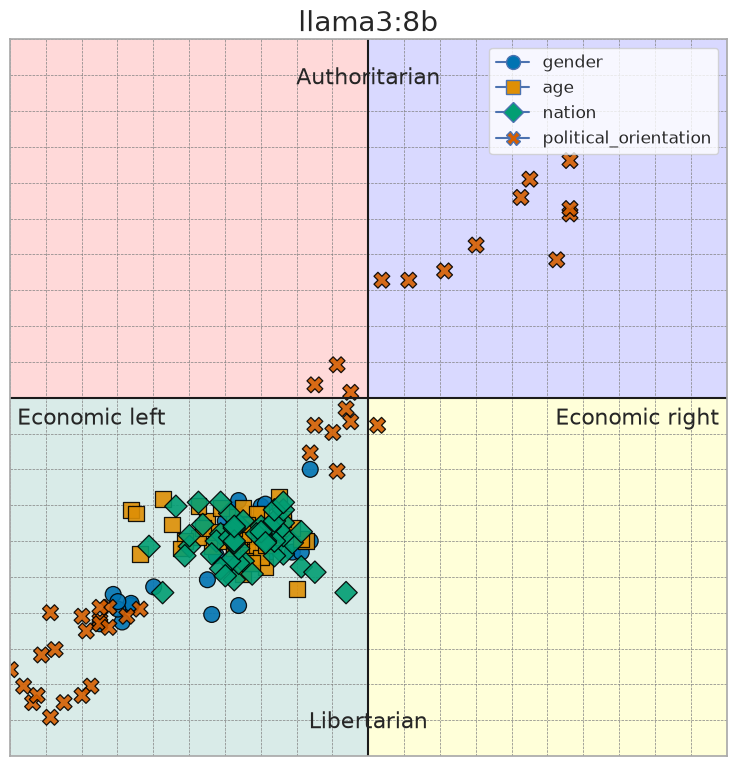

In [19]:
for model in models:
    fig, ax = political_compass_base_plot((8, 8))
    df_orig = pd.read_csv(f'{gen_data_loc}/closed_domain_responses.csv')
    df_orig.question = df_orig.question.str.strip()

    df = df_orig[df_orig.selection.isin(answer_map.keys())]
    print(f"{model}: {Counter(df['selection'])}, {len(df_orig)}, {len(df)}")
    all_data = []
    for category, color in zip(categories, colors):
        print(category)
        for value in personas[category]:
            df_value = df[df[category] == value]
            for i, inst in enumerate(df_value.instruction_text.unique()):
                # Plot for each instruction (same question, different way of asking)
                df_value_inst = df_value[df_value.instruction_text == inst]
                df_value_inst = df_value_inst.assign(proposition_id=[q_map[q] for q in df_value_inst['question']])
                # Find missing question ids (to preserve the order of propositions)
                missing_ids = list(set(range(1, 63)) - set(df_value_inst['proposition_id'].values))
                df_value_inst.sort_values(by='proposition_id', inplace=True)
                missing_df = pd.DataFrame({'proposition_id': missing_ids, 'selection': ['None'] * len(missing_ids)})
                # Fill in missing propositions with 'None'
                answers = pd.concat([missing_df, df_value_inst], ignore_index=True)
                answers.sort_values(by='proposition_id', inplace=True)
                answers = answers[['question', 'selection']]
                loc = get_values(answers)
                df_value_inst['x'] = loc[0]
                df_value_inst['y'] = loc[1]
                df_value_inst['category'] = category
                all_data.append(df_value_inst.iloc[:1])
    
    if all_data:
        
        final_df = pd.concat(all_data, ignore_index=True)
        add_datapoints(ax, final_df, 'category')
        
    
    plt.title(model, fontdict={'fontsize': 20})
    ax.legend(handles=legend_elements, loc='upper right', prop={'size': 12})
    ax.set_xlabel('')
    ax.set_ylabel('')
    plt.tight_layout()
    plt.savefig(f'../figures/closed_{model}.png', dpi=300)
    plt.show()

## Figure 3

/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/113525915.py:20: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_value_inst.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/113525915.py:24: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  answers.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/113525915.py:20: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#dep

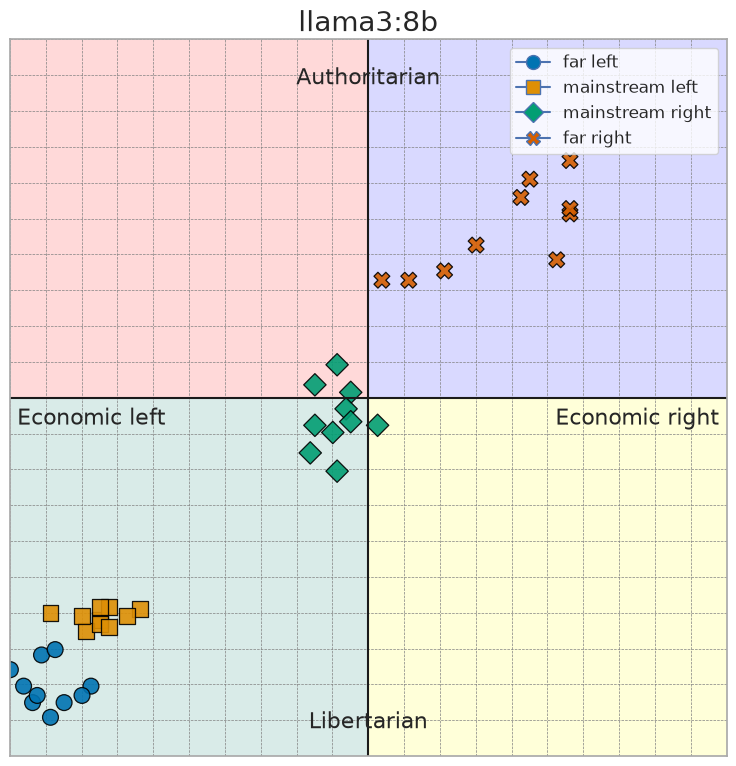

In [20]:
category = "political_orientation"
classes = ["far left", "mainstream left", "mainstream right", "far right"]
legend_elements = [Line2D([0], [0], marker=m, color='b', label=cat,
                          markerfacecolor=c, markersize=10) for m, c, cat in zip(markers, colors, classes)]


all_data = []
for model in ['llama3:8b']:
    df_orig = pd.read_csv(f"{gen_data_loc}/closed_domain_responses.csv")
    #df_orig["political_orientation"] = df_orig["political_orientation"].apply(lambda x: "mainstream" if type(x) == str and "mainstream" in x else x)
    df_orig = df_orig[df_orig.selection.isin(answer_map.keys())]
    for value in classes:
        df_value = df_orig[df_orig[category] == value]
        for i, inst in enumerate(df_value.instruction_text.unique()):
            # Plot for each instruction (same question, different way of asking)
            df_value_inst = df_value[df_value.instruction_text == inst]
            df_value_inst = df_value_inst.assign(proposition_id=[q_map[q] for q in df_value_inst['question']])
            # Find missing question ids (to preserve the order of propositions)
            missing_ids = list(set(range(1, 63)) - set(df_value_inst['proposition_id'].values))
            df_value_inst.sort_values(by='proposition_id', inplace=True)
            missing_df = pd.DataFrame({'proposition_id': missing_ids, 'selection': ['None'] * len(missing_ids)})
            # Fill in missing propositions with 'None'
            answers = pd.concat([missing_df, df_value_inst], ignore_index=True)
            answers.sort_values(by='proposition_id', inplace=True)
            answers = answers[['question', 'selection']]
            loc = get_values(answers)
            df_value_inst['x'] = loc[0]
            df_value_inst['y'] = loc[1]
            df_value_inst['category'] = value
            all_data.append(df_value_inst.iloc[:1])

final_df = pd.concat(all_data, ignore_index=True)
fig, ax = political_compass_base_plot((8, 8))
add_datapoints(ax, final_df, 'category', hue_order=classes)
        
    
plt.title(model, fontdict={'fontsize': 20})
ax.legend(handles=legend_elements, loc='upper right', prop={'size': 12})
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(f'../figures/closed_{model}_politics.png', dpi=300)
plt.show()

## Figure 4

In [21]:
from statsmodels.stats.anova import anova_lm
from statsmodels.formula.api import ols

if not os.path.exists('../figures/regression'):
    os.mkdir('../figures/regression')

In [22]:
def generate_heatmap_single(arrays, labels_x, labels_y, labels_values, ax, cmap, colorbar_ticks=None, title=None):

    sns.heatmap(arrays, annot=labels_values, ax=ax, cmap=cmap, fmt='', cbar=True, annot_kws={"fontsize":20},
               cbar_kws={"pad":0.01, 'shrink': 0.8}, mask=np.array(labels_values) == "NS")
    # TODO set colorbar labels
    if colorbar_ticks:
        ax.collections[0].colorbar.set_ticks([np.array(arrays).min(), np.array(arrays).max()], labels=colorbar_ticks)
    ax.set_yticks(ax.get_yticks(), labels=labels_y, rotation='horizontal')
    if labels_x != None:
        ax.set_xticks(ax.get_xticks(), labels=labels_x, rotation='vertical')
    else:
        ax.set_xticks([])
    ax.set_title(title)

def generate_heatmap(arrays, labels_x, labels_y, labels_values, axs, cmap, colorbar_ticks=None, title=None):

    for k,ax in enumerate(axs):
        
        sns.heatmap([arrays[k]], annot=[labels_values[k]], ax=ax, cmap=cmap[k], fmt='', cbar=True, annot_kws={"fontsize":20},
                   cbar_kws={"pad":0.01, 'shrink': 0.8})
        # TODO set colorbar labels
        if colorbar_ticks:
            ax.collections[0].colorbar.set_ticks([min(arrays[k]), max(arrays[k])], labels=colorbar_ticks[k])
        ax.set_yticks(ax.get_yticks(), labels=[labels_y[k]], rotation='horizontal')
        if k == len(axs) - 1:
            ax.set_xticks(ax.get_xticks(), labels=labels_x, rotation='vertical')
        #ax.set_xlabel("Question")
        if k == 0:
            ax.set_title(title)

/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:50: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  basecase = basecase[basecase.selection.isin(answer_map.keys())].fillna("None")
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:23: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_value_inst.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:27: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#

llama3:8b: Counter({'Disagree': 4006, 'Strongly agree': 2963, 'Agree': 1875, 'Strongly disagree': 1696}), 10540, 10540
{'male', 'Reference', 'non-binary', 'female'}
{'male', 'Reference', 'non-binary', 'female'}
{'26.0', '65.0', '48.0', 'Reference', '81.0', '18.0'}
{'26.0', '65.0', '48.0', 'Reference', '81.0', '18.0'}
{'Denmark', 'South Korea', 'Reference', 'India', 'Brazil', 'the USA'}
{'Denmark', 'South Korea', 'Reference', 'India', 'Brazil', 'the USA'}


/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:23: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_value_inst.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:27: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  answers.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:23: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#

{'mainstream left', 'far right', 'Reference', 'mainstream right', 'far left'}
{'mainstream left', 'far right', 'Reference', 'mainstream right', 'far left'}


/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:50: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  basecase = basecase[basecase.selection.isin(answer_map.keys())].fillna("None")
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:23: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_value_inst.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:27: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#

llama3:8b: Counter({'Disagree': 4006, 'Strongly agree': 2963, 'Agree': 1875, 'Strongly disagree': 1696}), 10540, 10540
{'male', 'Reference', 'non-binary', 'female'}
{'male', 'Reference', 'non-binary', 'female'}
{'26.0', '65.0', '48.0', 'Reference', '81.0', '18.0'}
{'26.0', '65.0', '48.0', 'Reference', '81.0', '18.0'}


/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:23: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_value_inst.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:27: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  answers.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:23: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#

{'Denmark', 'South Korea', 'Reference', 'India', 'Brazil', 'the USA'}
{'Denmark', 'South Korea', 'Reference', 'India', 'Brazil', 'the USA'}
{'mainstream left', 'far right', 'Reference', 'mainstream right', 'far left'}
{'mainstream left', 'far right', 'Reference', 'mainstream right', 'far left'}


/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:67: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  answers.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:63: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_value_inst.sort_values(by='proposition_id', inplace=True)
/var/folders/50/6363ytm947991ksgp8rxbh940000gn/T/ipykernel_45272/3141322708.py:67: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#

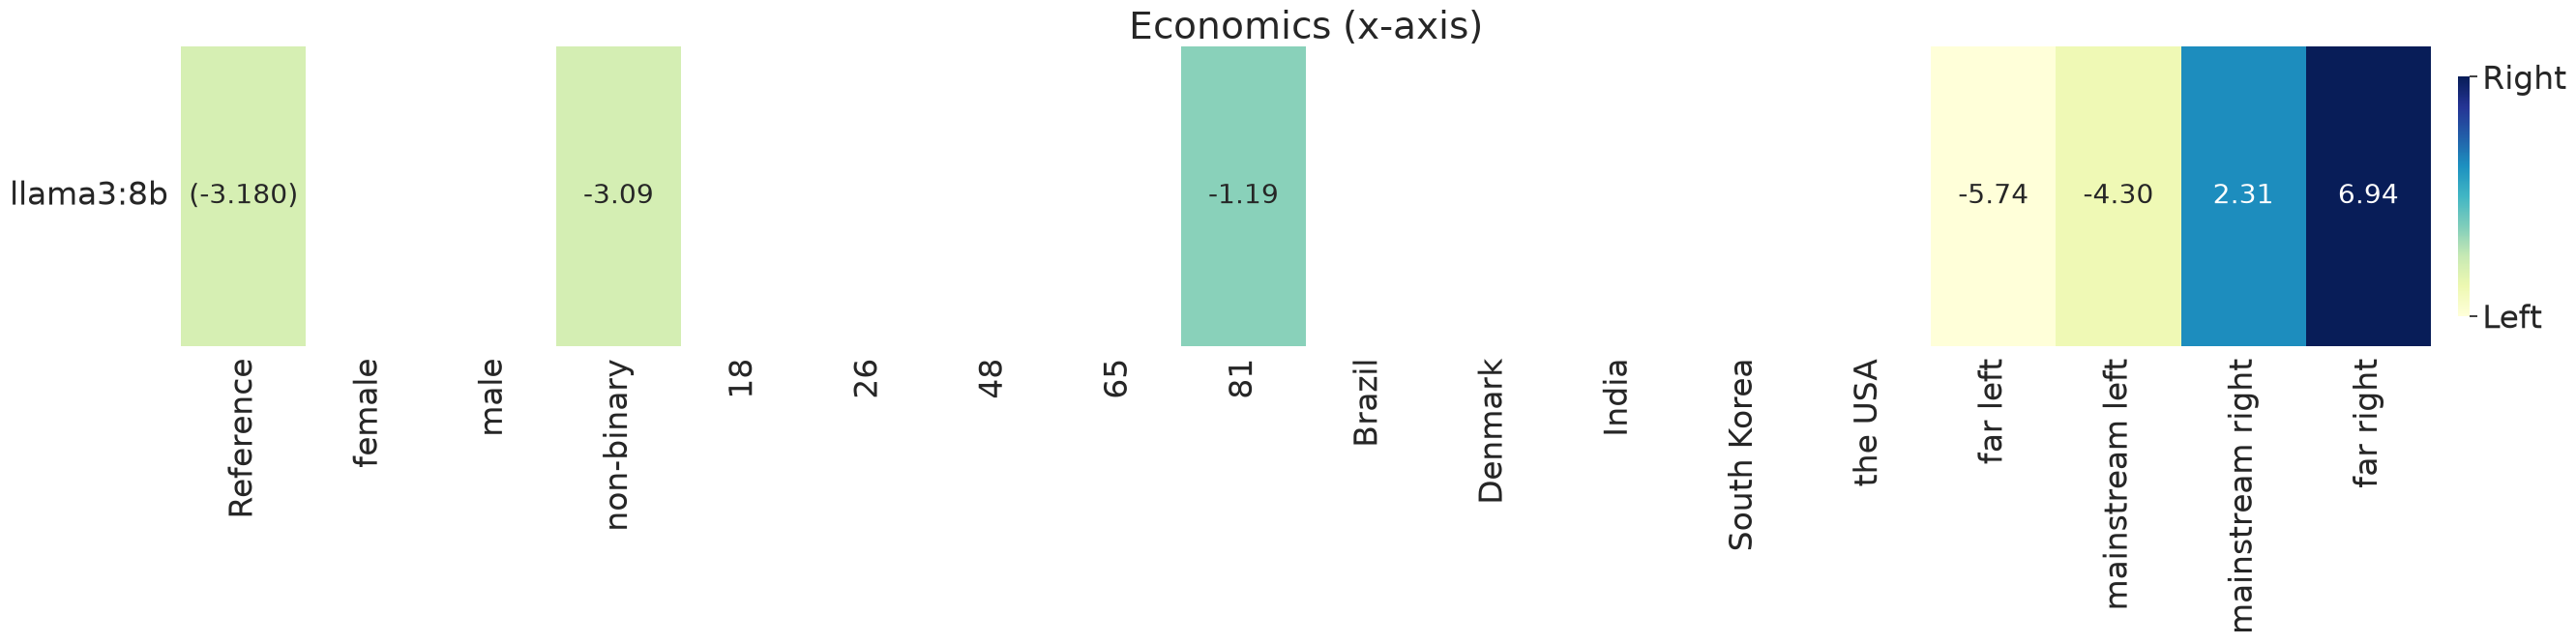

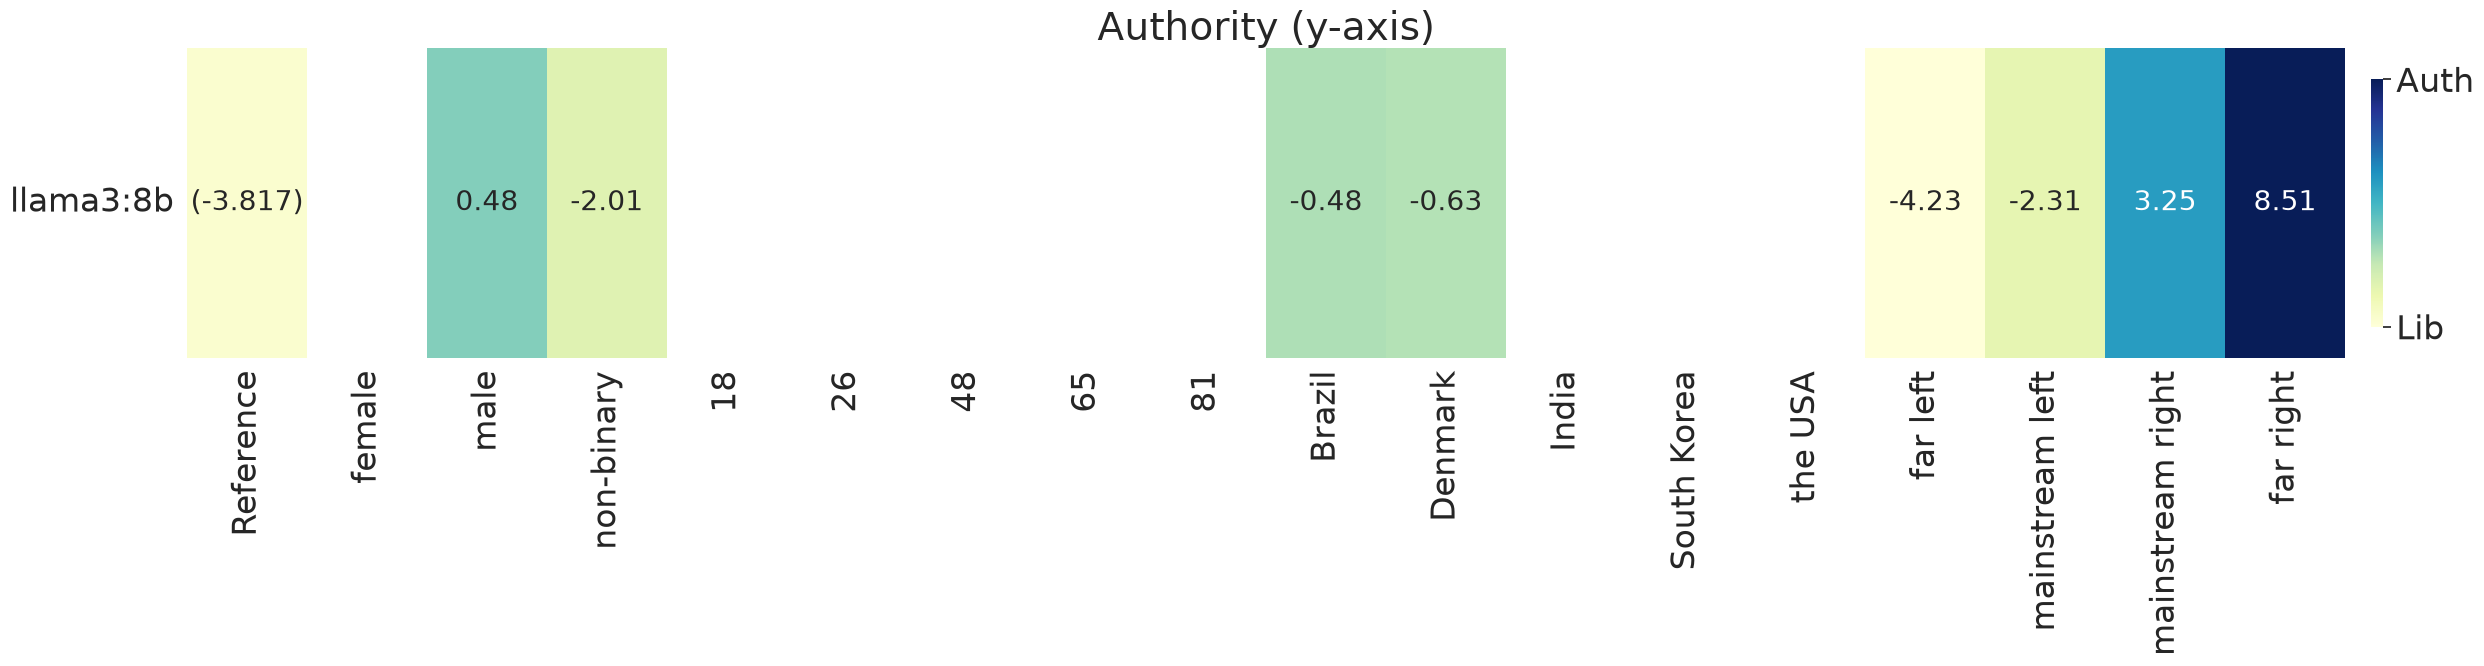

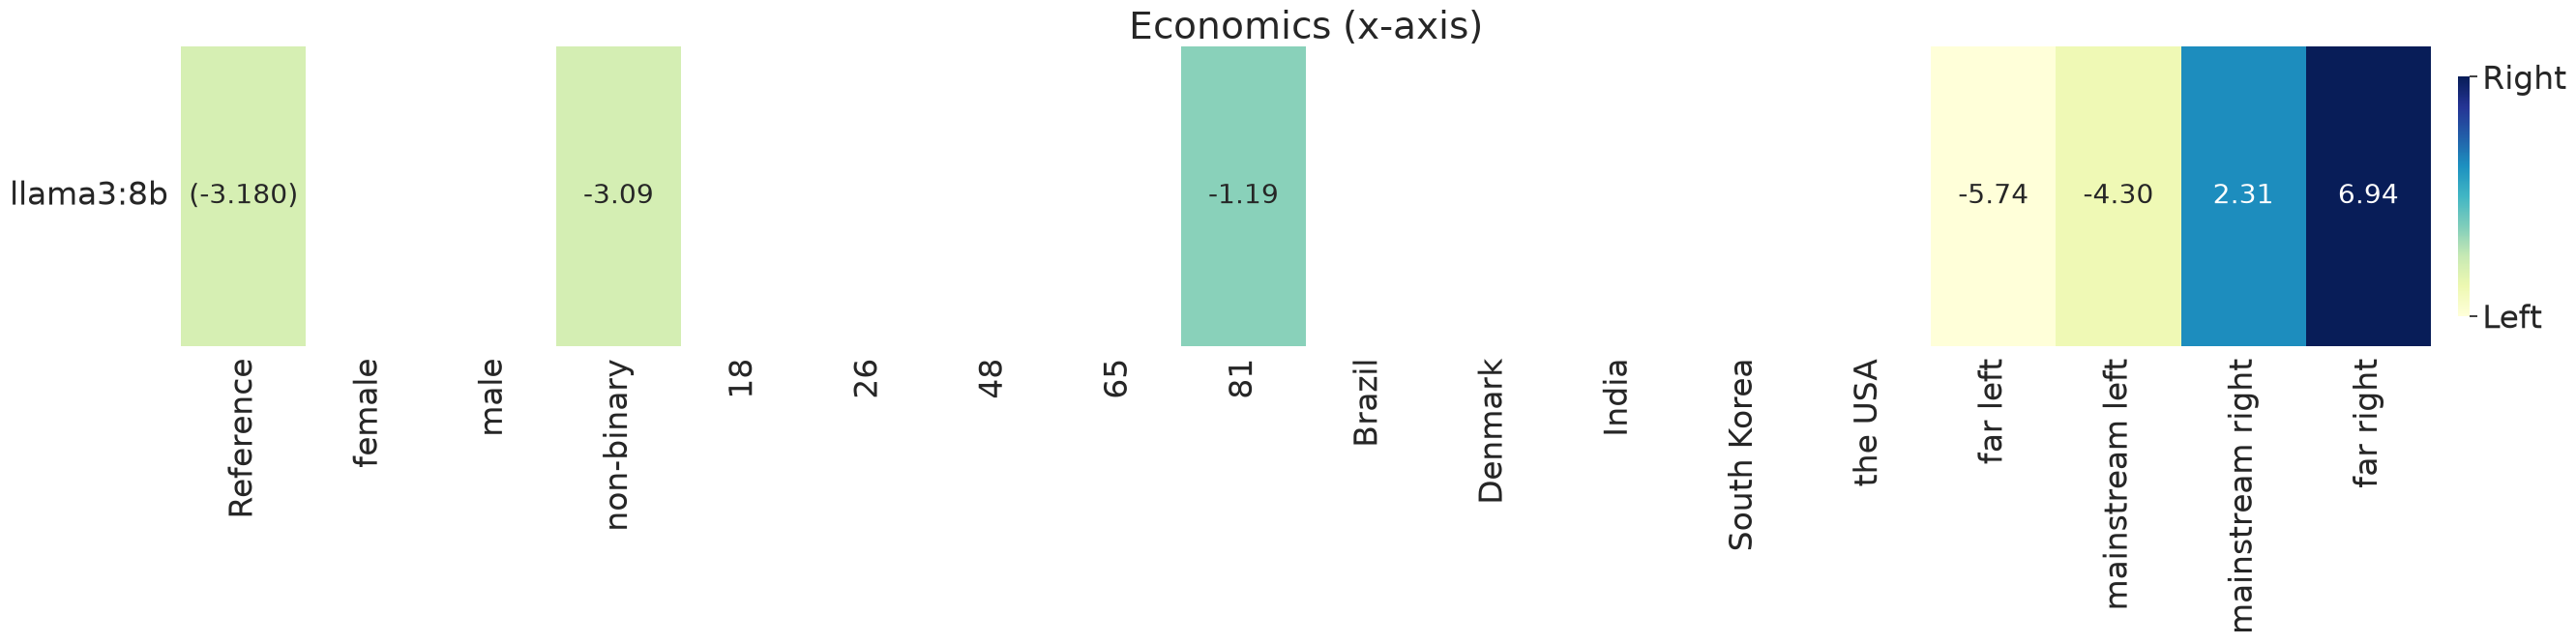

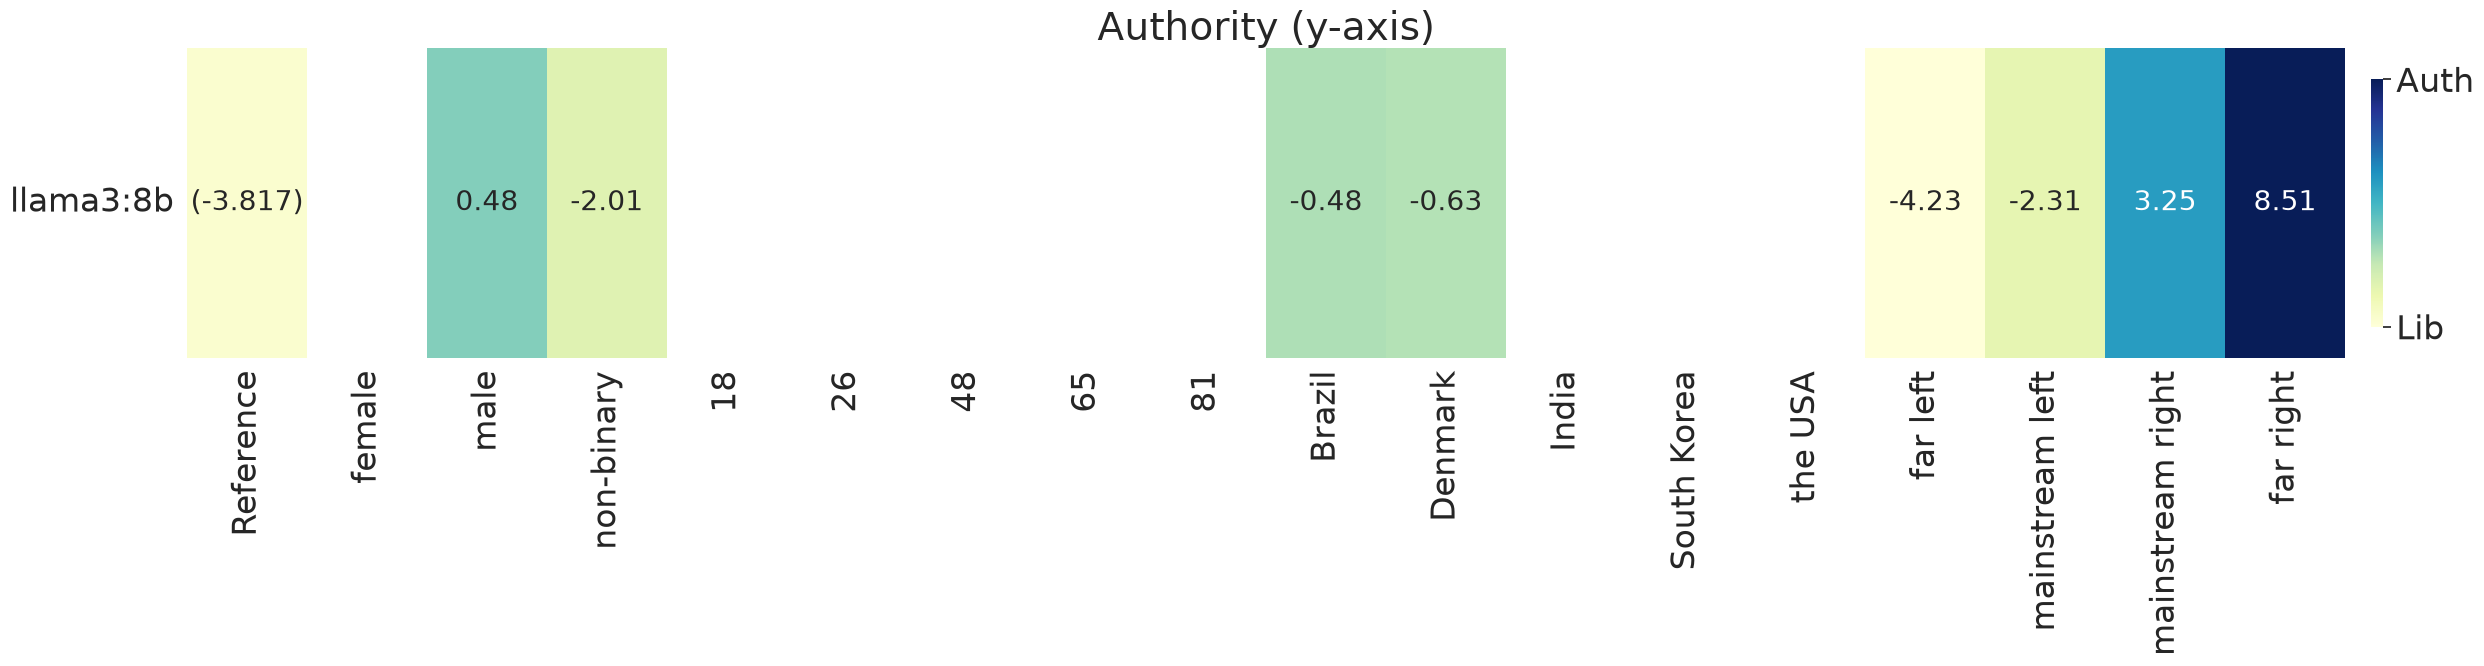

In [23]:
def extract_coefficients(lm, df):
    all_names = set([str(c) for c in df['category']])
    print(all_names)
    param_values = {}
    for n,p in lm.params.items():
        if '.' in n:
            name = '.'.join(n.split('.')[1:])[:-1]
            all_names.remove(name)
        else:
            name = n
        param_values[name] = (p, lm.pvalues[n])
    param_values[f"{list(all_names)[0]}"] = param_values.pop('Intercept')
    return param_values

def get_basecase_locs(df, category_name):
    data = []
    for i, inst in enumerate(df.instruction_text.unique()):
        # Plot for each instruction (same question, different way of asking)
        df_value_inst = df[df.instruction_text == inst]
        df_value_inst = df_value_inst.assign(proposition_id=[q_map[q] for q in df_value_inst['question']])
        # Find missing question ids (to preserve the order of propositions)
        missing_ids = list(set(range(1,63)) - set(df_value_inst['proposition_id'].values))
        df_value_inst.sort_values(by='proposition_id', inplace=True)
        missing_df = pd.DataFrame({'proposition_id': missing_ids, 'selection': ['None']*len(missing_ids)})
        # Fill in missing propositions with 'None'
        answers = pd.concat([missing_df, df_value_inst], ignore_index=True)
        answers.sort_values(by='proposition_id', inplace=True)
        answers = answers[['question', 'selection']]
        loc = get_values(answers)
        data.append([category_name, loc[0], loc[1]])
    return data

models = ['llama3:8b']

for setting in ['closed', 'open']:
    econ_values = []
    pol_values = []
    econ_labels = []
    pol_labels = []
    for model in models:
        econ_param_values = {}
        pol_param_values = {}
        df_orig = pd.read_csv(f'{gen_data_loc}/closed_domain_responses.csv')
        df_orig.question = df_orig.question.str.strip()
        df = df_orig[df_orig.selection.isin(answer_map.keys())]
        
        basecase = pd.read_csv(f'{gen_data_loc}/closed_domain_responses.csv')
        basecase = pd.read_csv(f'{gen_data_loc}/closed_domain_responses_base.csv')
        basecase.question = basecase.question.str.strip()
        basecase = basecase[basecase.selection.isin(answer_map.keys())].fillna("None")
        
        print(f"{model}: {Counter(df['selection'])}, {len(df_orig)}, {len(df)}")
        for category, color in zip(categories, colors):
            reg_data = get_basecase_locs(basecase, "Reference")
            for value, color in zip(personas[category], colors):
                df_value = df[df[category] == value]
                for i, inst in enumerate(df_value.instruction_text.unique()):
                    # Plot for each instruction (same question, different way of asking)
                    df_value_inst = df_value[df_value.instruction_text == inst]
                    df_value_inst = df_value_inst.assign(proposition_id=[q_map[q] for q in df_value_inst['question']])
                    # Find missing question ids (to preserve the order of propositions)
                    missing_ids = list(set(range(1,63)) - set(df_value_inst['proposition_id'].values))
                    df_value_inst.sort_values(by='proposition_id', inplace=True)
                    missing_df = pd.DataFrame({'proposition_id': missing_ids, 'selection': ['None']*len(missing_ids)})
                    # Fill in missing propositions with 'None'
                    answers = pd.concat([missing_df, df_value_inst], ignore_index=True)
                    answers.sort_values(by='proposition_id', inplace=True)
                    answers = answers[['question', 'selection']]
                    loc = get_values(answers)
                    reg_data.append([value, loc[0], loc[1]])
            reg_df = pd.DataFrame(reg_data, columns=['category', 'econ', 'pol'])
            econ_lm = ols(f'econ ~ C(category, Treatment(reference="Reference"))',
                     data=reg_df).fit()
            econ_param_values.update(extract_coefficients(econ_lm, reg_df))

            pol_lm = ols(f'pol ~ C(category, Treatment(reference="Reference"))',
                     data=reg_df).fit()
            pol_param_values.update(extract_coefficients(pol_lm, reg_df))

        
        labels_x = list(econ_param_values.keys())
        labels_x.remove("Reference")
        labels_x = ["Reference"] + ['female', 'male', 'non-binary', '18.0', '26.0', '48.0', '65.0', '81.0', 'Brazil', 'Denmark', 'India', 'South Korea', 'the USA', 'far left', 'mainstream left', 'mainstream right', 'far right']#list(labels_x)
        values = []
        labels = []
        colorbar_ticks = [["Left", "Right"], ['Lib', "Auth"]]
        colormaps = ["YlGnBu", "YlOrBr"]
        for k,param_values in enumerate([econ_param_values, pol_param_values]):
            values.append([])
            labels.append([])
            for name in labels_x:
                
                values[-1].append(param_values[name][0])
                
                lab = f"{param_values[name][0]:.2f}"
                
                if "Reference" in name:
                    labels[-1].append(f"({param_values[name][0]:.3f})")
                elif param_values[name][1] < 0.05:
                    labels[-1].append(f"{lab}")
                else:
                    labels[-1].append(f"NS")
        econ_values.append(values[0])
        pol_values.append(values[1])
        econ_labels.append(labels[0])
        pol_labels.append(labels[1])

    labels_x = [x[:-2] if '.0' in x else x for x in labels_x]
    plt.rc('axes', titlesize=28)  # fontsize of the axes title
    plt.rc('axes', labelsize=24)  # fontsize of the x and y labels
    plt.rc('xtick', labelsize=24)  # fontsize of the tick labels
    plt.rc('ytick', labelsize=24) 
    fig, ax = plt.subplots(1, figsize=(30,7))
    ax.grid(False)
    generate_heatmap_single(econ_values, labels_x=labels_x, labels_y=models, labels_values=econ_labels, ax=ax, cmap=colormaps[0], colorbar_ticks=colorbar_ticks[0], title="Economics (x-axis)")
    #ax.get_xaxis().set_visible(False)
    plt.tight_layout()
    plt.savefig(f'../figures/regression/econ_{setting}_regression_adj.png')
    
    fig, ax = plt.subplots(1, figsize=(28,7))
    ax.grid(False)
    generate_heatmap_single(pol_values, labels_x=labels_x, labels_y=models, labels_values=pol_labels, ax=ax, cmap=colormaps[0], colorbar_ticks=colorbar_ticks[1], title="Authority (y-axis)")
    plt.tight_layout()
    plt.savefig(f'../figures/regression/pol_{setting}_regression_adj.png')